# CF-JEPA: planning past distractors

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/cfjepa.ipynb)

[CF-JEPA](https://arxiv.org/abs/2610.00727) (code not released) splits a LeWM-style latent into a controllable part and an uncontrollable part. An action-conditioned predictor advances the first, an action-free one the second; an inverse model pulls the action into the controllable part, and an adversary behind a gradient reversal layer pushes it out of the other. The planner compares only the controllable part with the goal, so things that move on their own stop counting as distance.

Here a point crosses two rooms while three colored discs drift through the picture, ignoring the actions. The goal image has the discs somewhere else.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import CFJEPA, LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data and model
The point wanders at random, keeping its previous action 80% of the time, while three discs drift on their own: 1024 episodes of 65 steps. Both models get the same small ViT encoder and a predictor of the same depth; CF-JEPA uses 96 of the 128 latent dimensions as its controllable part and gives the other 32 a half-depth, action-free predictor. LeWM is the same model without the split.

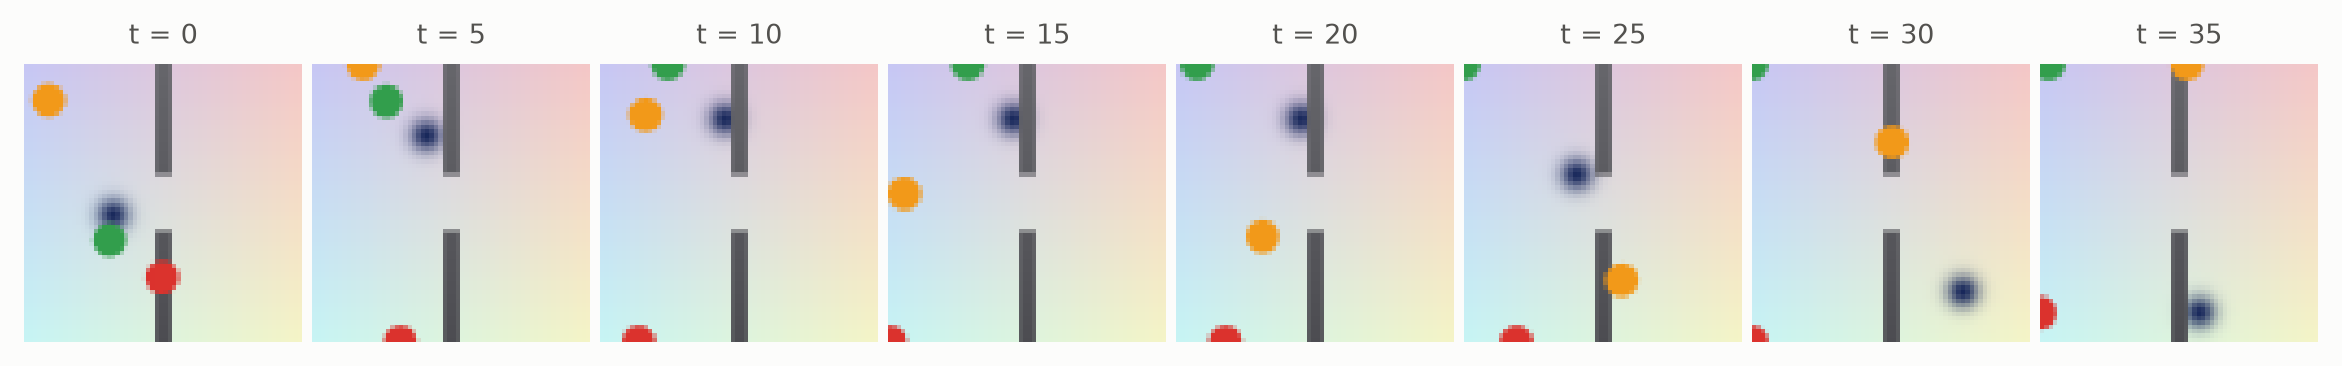

In [3]:
data = TwoRooms(batch_size=1024, distractors=3, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=4), batch_size=128, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, :40:5], titles=[f"t = {t}" for t in range(0, 40, 5)])

In [4]:
def encoder():
    return CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)


predictor = dict(depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.09)
models = {
    "CF-JEPA": CFJEPA(encoder(), action_dim=2, embed_dim=128, ctrl_dim=96, alpha=3.0, beta=1.0, **predictor),
    "LeWM": LeWM(encoder(), action_dim=2, embed_dim=128, **predictor),
}
for name, model in models.items():
    print(f"{name:8s} {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

CF-JEPA  2.18M parameters
LeWM     2.34M parameters


## Train
Next-embedding MSE and SIGReg for both, plus CF-JEPA's inverse-dynamics loss on the controllable part ($\alpha = 3$, the paper's Two-Room value) and the adversarial action loss on the uncontrollable part ($\beta = 1$). The adversary's loss should stay near 1/3, the variance of uniform actions in $[-1, 1]$ and the loss of a constant guess: the encoder is trained to keep it from recovering the action.

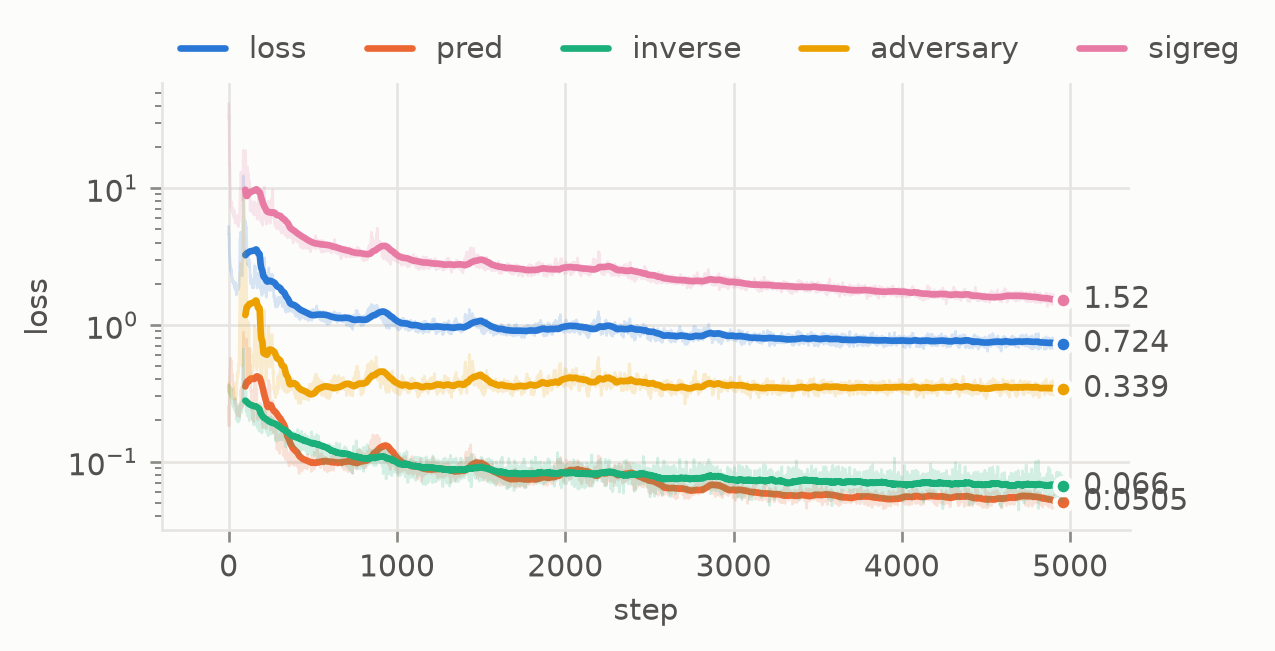

In [5]:
logs = {name: fit(model.to(device), loader, epochs=10, lr=5e-4) for name, model in models.items()}
plots.curves(logs["CF-JEPA"], smooth=100)

## Where the distractors go
Render the same 256 point positions under 8 random placements of the discs and encode them. For each latent (CF-JEPA's two parts, LeWM's whole embedding) the share of its variance that comes from the discs is the variance across placements over the total. A planner that compares latents wants this share near zero.

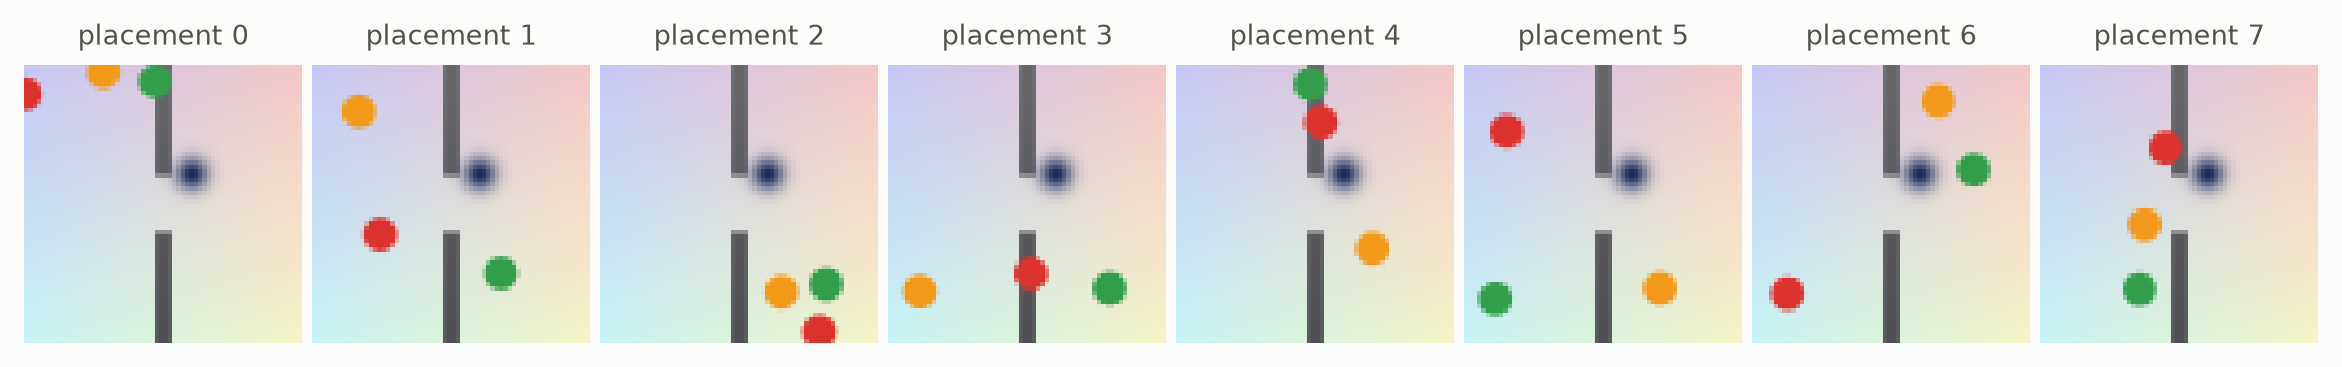

In [6]:
probe = TwoRooms(batch_size=256, distractors=3)
states = probe.free(256, generator=torch.Generator().manual_seed(2))
gen = torch.Generator().manual_seed(3)
images = []
for _ in range(8):
    probe.reset(states, generator=gen)  # new disc placements, same point positions
    images.append(probe.render(states))
images = torch.stack(images, 1)  # (256, 8, 3, 64, 64)
plots.images(images[0], titles=[f"placement {k}" for k in range(8)])

In [7]:
def distractor_share(z):  # z: (positions, placements, D)
    return (z.var(1).mean() / z.flatten(0, 1).var(0).mean()).item()


with torch.no_grad():
    z_cf = models["CF-JEPA"].encode(images.to(device))
    z_le = models["LeWM"].encode(images.to(device))
zc, zu = models["CF-JEPA"].split(z_cf)
share = {
    "CF-JEPA controllable": distractor_share(zc),
    "CF-JEPA uncontrollable": distractor_share(zu),
    "LeWM": distractor_share(z_le),
}
for name, s in share.items():
    print(f"{name:24s} {s:6.1%} of the variance comes from the discs")

CF-JEPA controllable      21.4% of the variance comes from the discs
CF-JEPA uncontrollable    82.5% of the variance comes from the discs
LeWM                      62.4% of the variance comes from the discs


## Plan toward goal images
CEM searches 8 actions (128 samples, 16 elites, 5 iterations, averaging the cost along the path) and the policy runs the first one and plans again, for 60 steps; an episode succeeds when the point comes within 0.1 of the goal, as in the [main benchmark](../comparisons/main_benchmark.ipynb). Goal images are rendered with the discs elsewhere. Besides the training setting, three shifts the models never saw: no discs, five discs (two in new colors), and three discs on a tinted floor. Each setting has 64 tasks with the goal in the same room and 64 in the other room, through the door.

In [8]:
cem = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
settings = {
    "3 discs (training)": dict(distractors=3),
    "no discs": dict(distractors=0),
    "5 discs": dict(distractors=5),
    "3 discs, tinted floor": dict(distractors=3, floor=(0.55, 0.75, 0.95)),
}
results, goals = {}, {}
for setting, kwargs in settings.items():
    env = TwoRooms(batch_size=64, device=device, **kwargs)
    for task, same_room in [("same room", True), ("other room", False)]:
        start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
        goals[setting, task] = goal
        goal_images = env.render(goal)
        policies = {name: evaluation.goal_policy(model, cem, goal_images) for name, model in models.items()}
        policies["random actions"] = evaluation.random_policy(env)
        results[setting, task] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
        print(f"== {setting}, {task}\n{results[setting, task]}")

== 3 discs (training), same room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA            84% [74%, 91%]      84%    3.11          0.0368      0.85   0.118       0.554   1.21e+03
LeWM               94% [85%, 98%]      94%    12.2           0.113     0.491    0.13       0.689      1e+03
random actions     47% [35%, 59%]      47%    19.9           0.316   -0.0348   0.027        1.04     0.0136


== 3 discs (training), other room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA             16% [9%, 26%]      16%    10.2            0.65    -0.062  0.0397       0.633   1.21e+03
LeWM               44% [32%, 56%]      44%    27.9           0.384     0.407  0.0886       0.708      1e+03
random actions       5% [2%, 13%]       5%      18           0.609    0.0244 0.00458        1.05     0.0139


== no discs, same room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA            89% [79%, 95%]      89%    2.39          0.0245     0.906   0.178       0.435   1.21e+03
LeWM               91% [81%, 96%]      91%    2.86          0.0397     0.848   0.266       0.419      1e+03
random actions     56% [44%, 68%]      56%    18.6           0.307    0.0212  0.0324        1.05     0.0134


== no discs, other room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA             11% [5%, 21%]      11%    5.14           0.705     -0.12  0.0286       0.536   1.21e+03
LeWM               17% [10%, 28%]      17%    8.45           0.694   0.00408  0.0577       0.557      1e+03
random actions      16% [9%, 26%]      16%    36.8           0.585  -0.00532  0.0219        1.04     0.0134


== 5 discs, same room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA            89% [79%, 95%]      89%    9.68          0.0904     0.617  0.0924       0.727   1.21e+03
LeWM               77% [65%, 85%]      77%    11.6           0.214    0.0498   0.081       0.668      1e+03
random actions     50% [38%, 62%]      50%    15.9           0.324   0.00933  0.0283        1.05     0.0142


== 5 discs, other room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA            25% [16%, 37%]      25%    15.2           0.533    0.0545  0.0483        0.76   1.21e+03
LeWM               41% [29%, 53%]      41%    32.3           0.481     0.275  0.0756       0.659      1e+03
random actions       8% [3%, 17%]       8%    33.2           0.582    0.0269  0.0116        1.04     0.0137


== 3 discs, tinted floor, same room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA            20% [12%, 32%]      25%    1.69           0.529    -0.645  0.0601       0.227   1.21e+03
LeWM               36% [25%, 48%]      42%    10.1           0.564    -0.646  0.0536       0.304      1e+03
random actions     56% [44%, 68%]      56%    19.9           0.306   -0.0532  0.0342        1.04     0.0136


== 3 discs, tinted floor, other room
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CF-JEPA               2% [0%, 8%]       2%       6           0.583     -0.11 0.00357       0.239   1.21e+03
LeWM                 3% [1%, 11%]       3%    33.5           0.726    -0.145 0.00824       0.303      1e+03
random actions       5% [2%, 13%]       5%      48           0.636 -0.000762 0.00702        1.02     0.0138


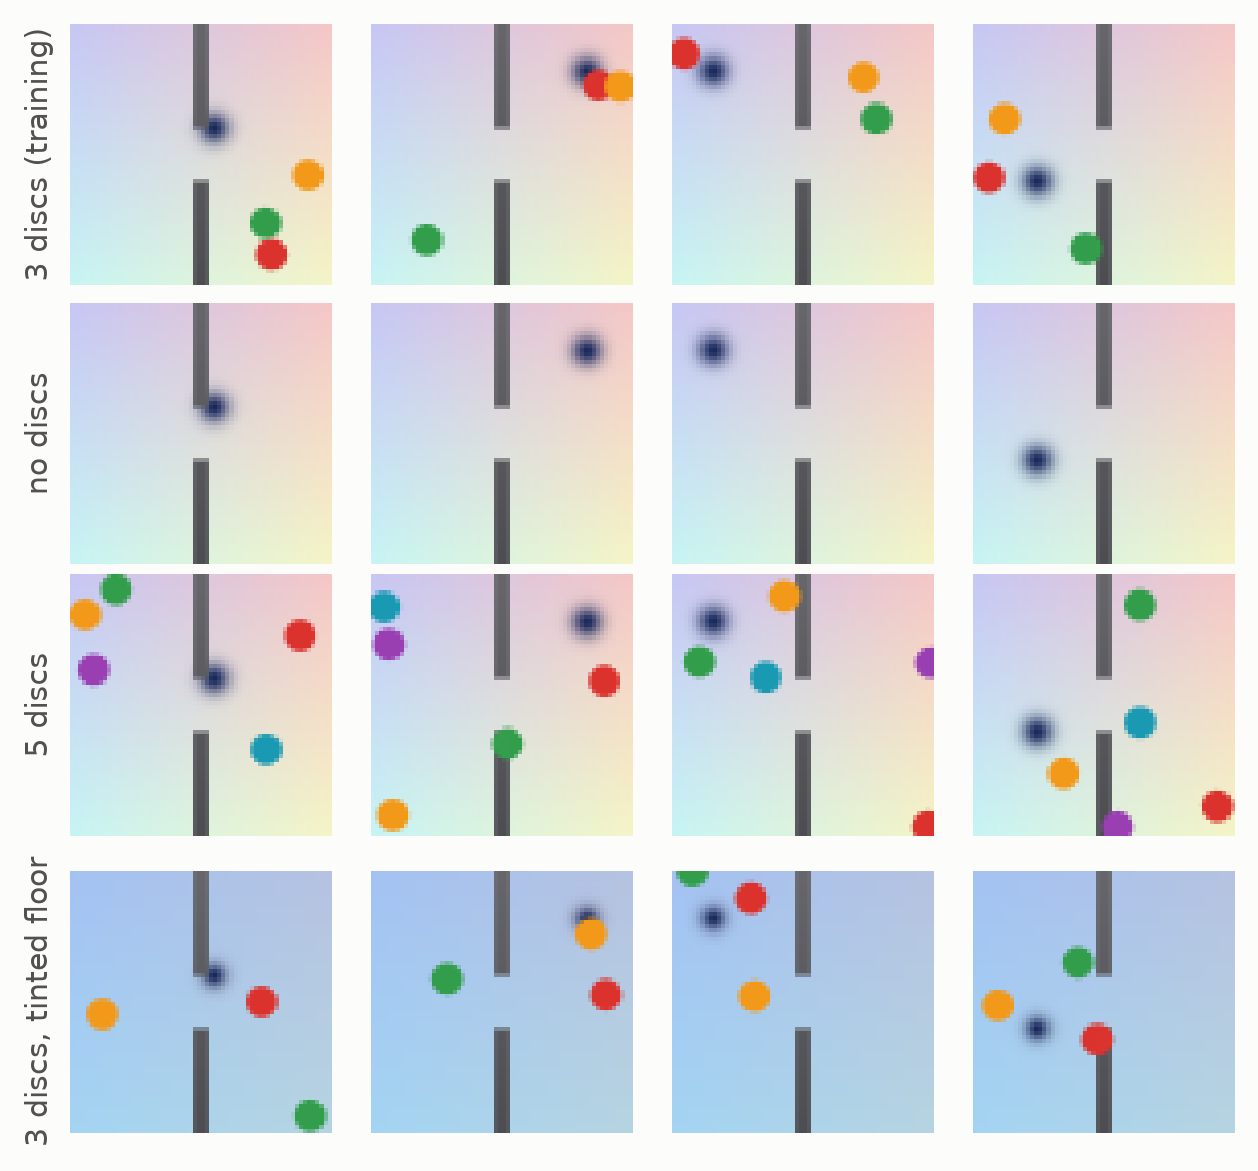

In [9]:
shifted = {name: TwoRooms(batch_size=4, **kwargs).render(start[:4].cpu()) for name, kwargs in settings.items()}
plots.images(torch.cat(list(shifted.values())), ncols=4, rows=list(shifted))

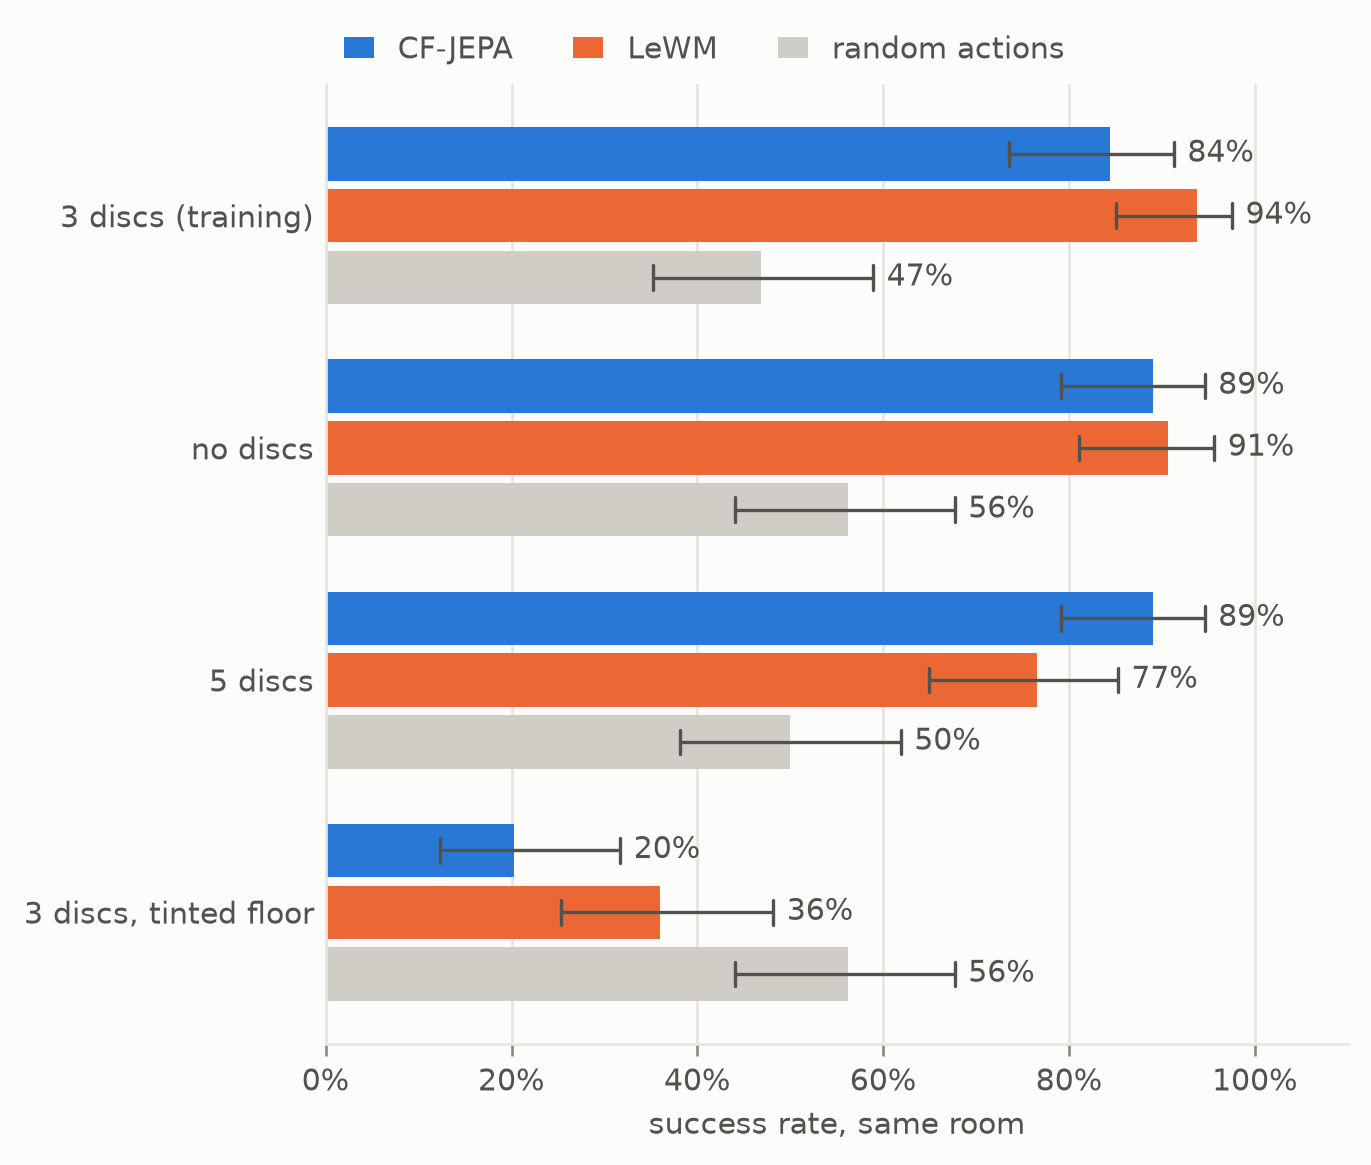

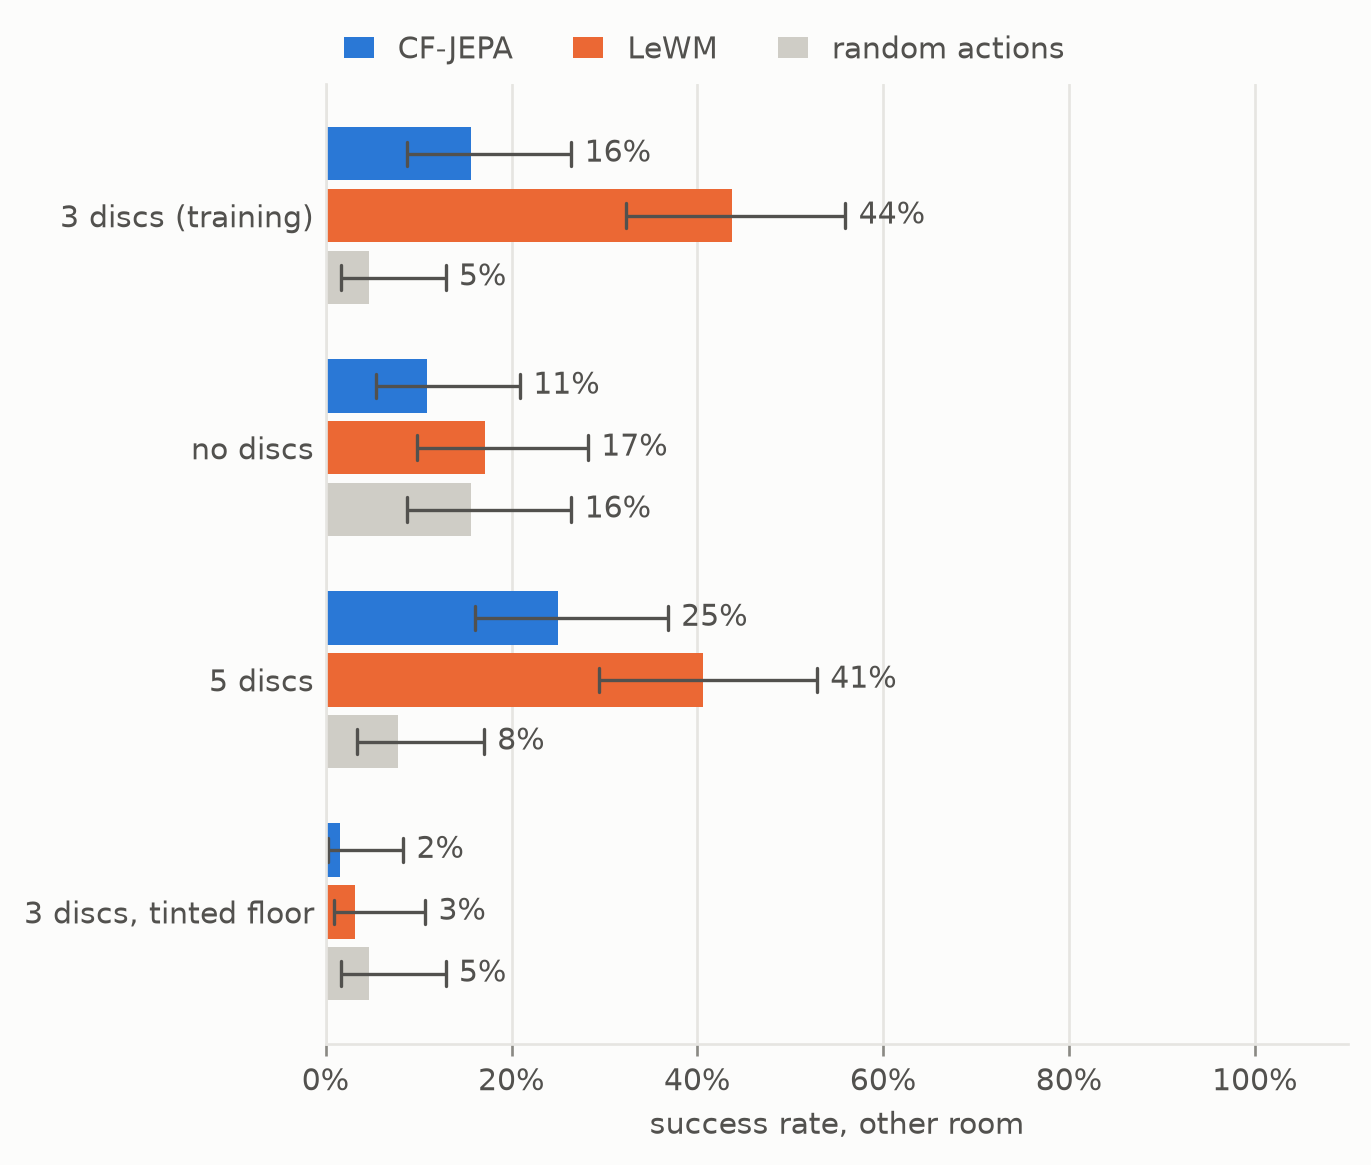

In [10]:
for task in ["same room", "other room"]:
    display(plots.bars({s: results[s, task].intervals() for s in settings}, xlabel=f"success rate, {task}", baseline="random actions"))

## Across the door
Where do the episodes toward the other room go? Paths of the first 8 tasks in the training setting, and, per model, the share of episodes that end in the goal's room and the share that end against the wall (within 0.1 of it, on the start side).

CF-JEPA  ends in the goal's room   16%, against the wall   27%


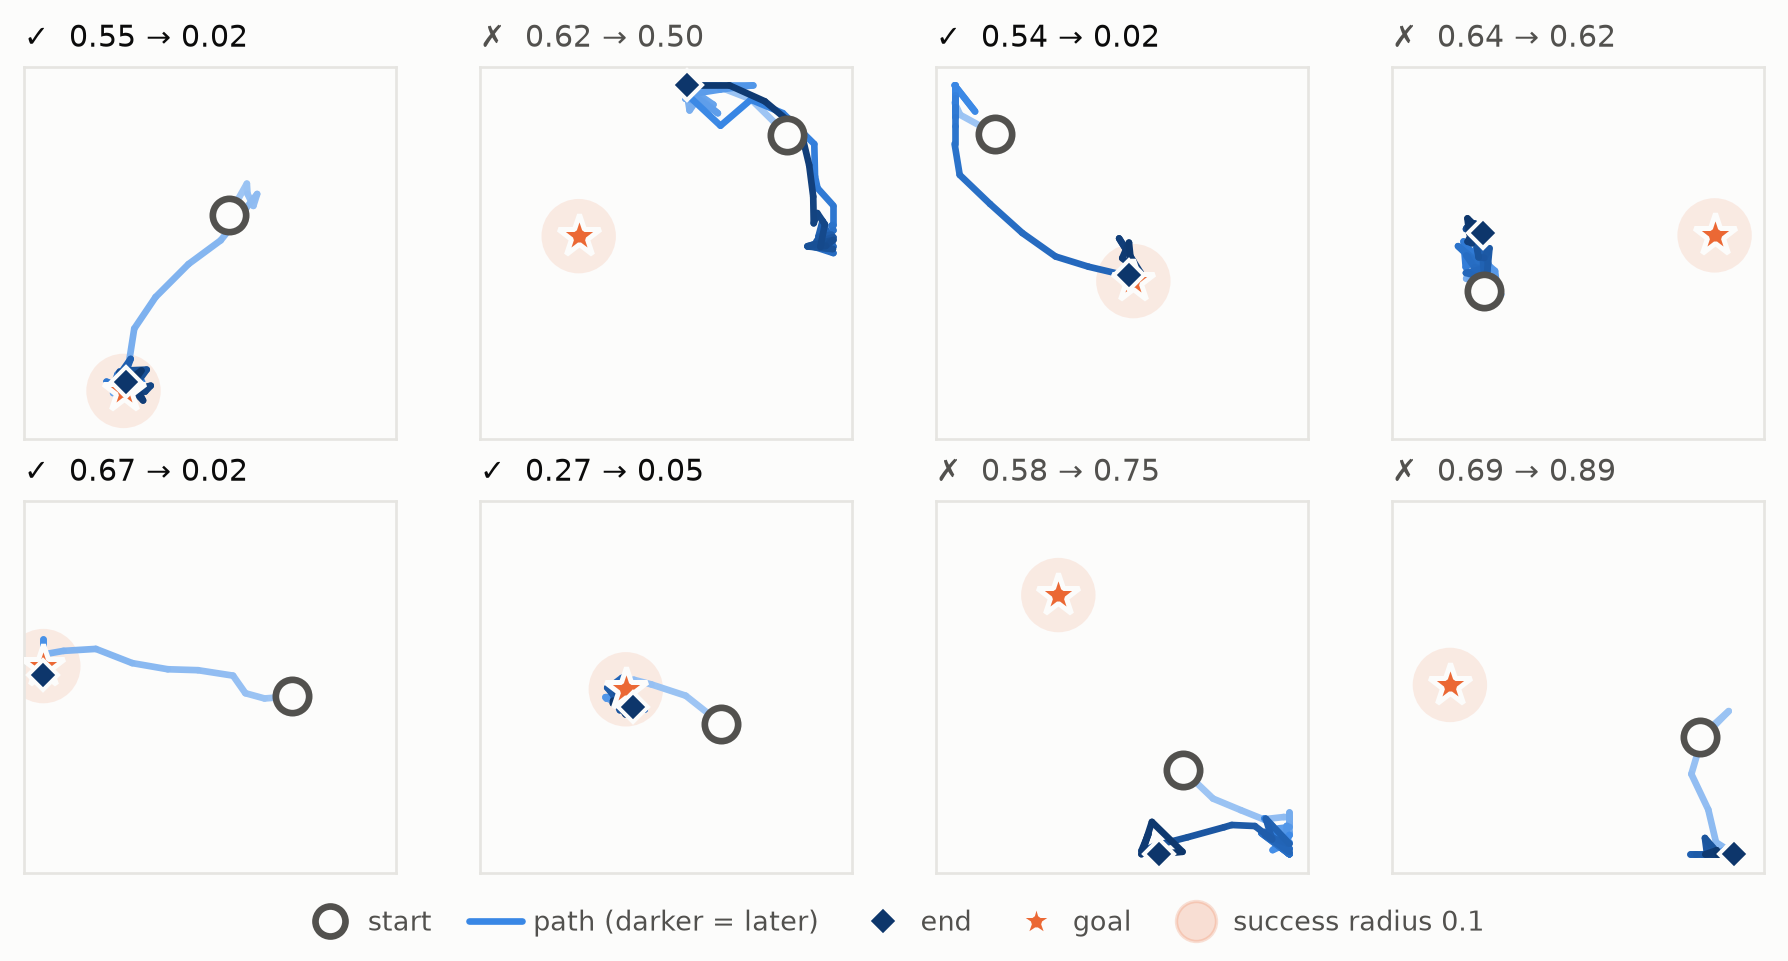

LeWM     ends in the goal's room   41%, against the wall   19%


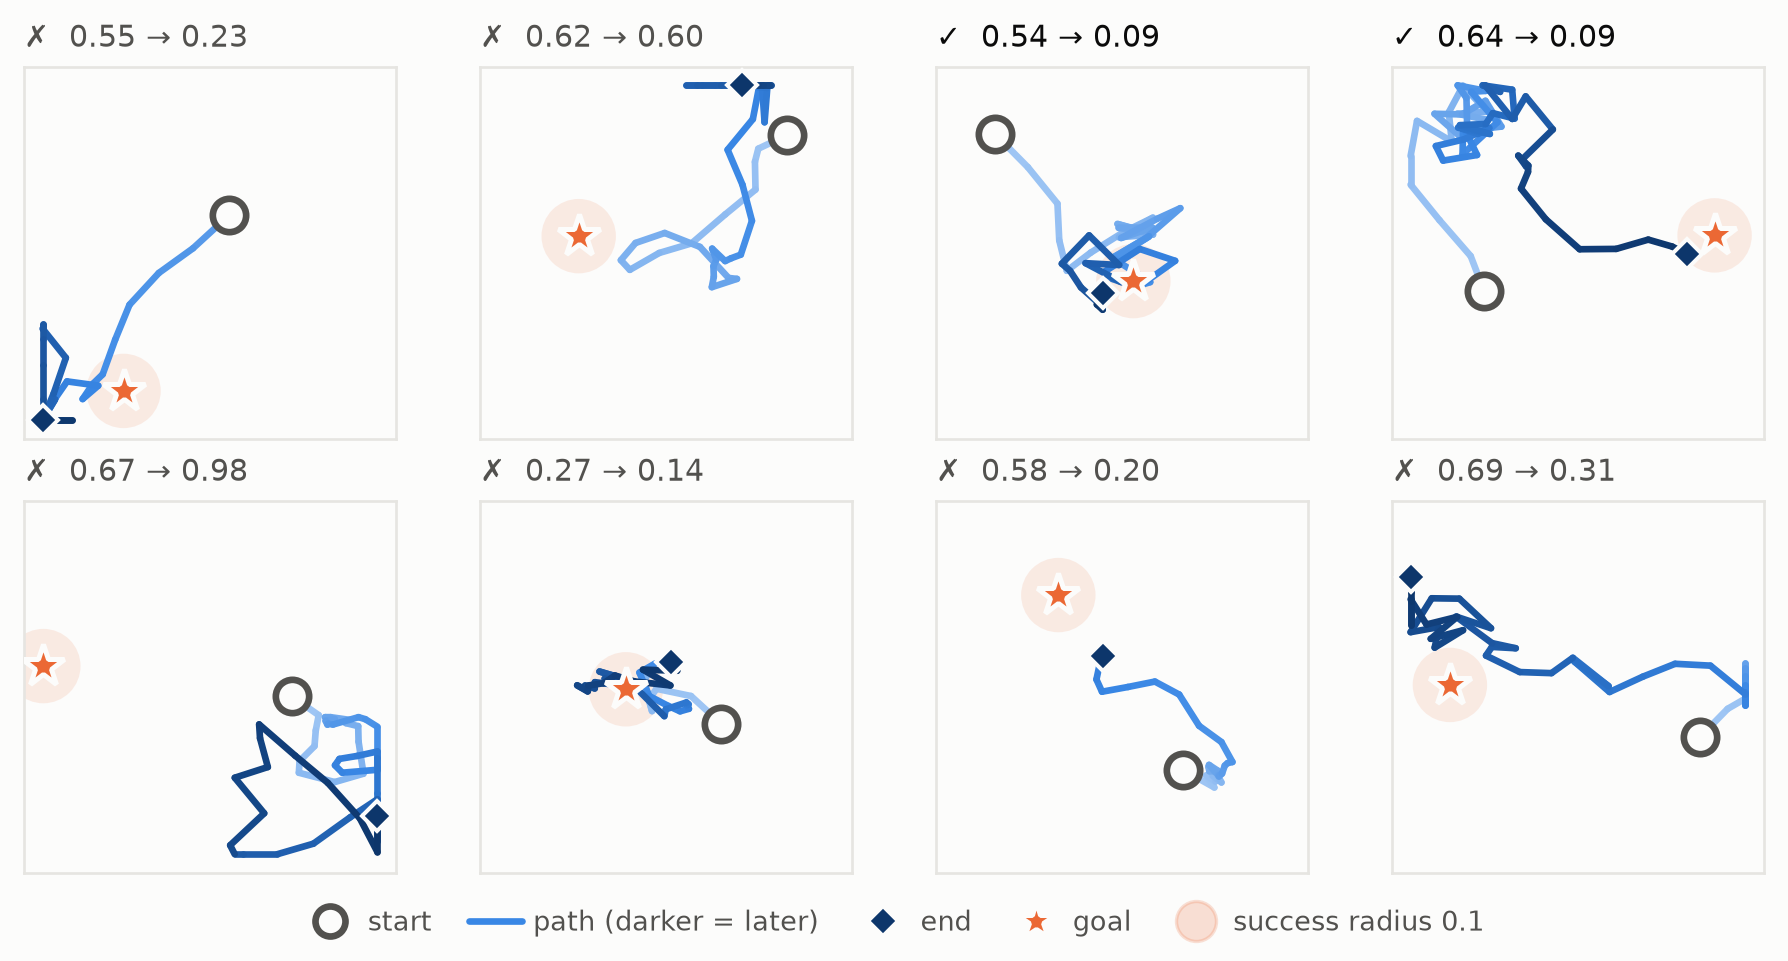

In [11]:
key = ("3 discs (training)", "other room")
goal = goals[key].cpu()
for name in models:
    final = results[key].paths[name][:, -1].cpu()
    in_goal_room = (final[:, 0] > 0.5) == (goal[:, 0] > 0.5)
    at_wall = ~in_goal_room & ((final[:, 0] - 0.5).abs() < 0.1)
    print(f"{name:8s} ends in the goal's room {in_goal_room.float().mean():5.0%}, against the wall {at_wall.float().mean():5.0%}")
    display(plots.trajectories(results[key].paths[name][:8].cpu(), goal[:8]))

## Summary
Success with its 95% Wilson interval, per setting and task:

In [12]:
names = [*models, "random actions"]
print(f"{'':36s}" + "".join(f"{n:>20s}" for n in names))
for (setting, task), result in results.items():
    rates = result.intervals()
    print(f"{setting + ', ' + task:36s}" + "".join(f"{rates[n]!s:>20}" for n in names))

                                                 CF-JEPA                LeWM      random actions
3 discs (training), same room             84% [74%, 91%]      94% [85%, 98%]      47% [35%, 59%]
3 discs (training), other room             16% [9%, 26%]      44% [32%, 56%]        5% [2%, 13%]
no discs, same room                       89% [79%, 95%]      91% [81%, 96%]      56% [44%, 68%]
no discs, other room                       11% [5%, 21%]      17% [10%, 28%]       16% [9%, 26%]
5 discs, same room                        89% [79%, 95%]      77% [65%, 85%]      50% [38%, 62%]
5 discs, other room                       25% [16%, 37%]      41% [29%, 53%]        8% [3%, 17%]
3 discs, tinted floor, same room          20% [12%, 32%]      36% [25%, 48%]      56% [44%, 68%]
3 discs, tinted floor, other room            2% [0%, 8%]        3% [1%, 11%]        5% [2%, 13%]


The factorization works as a representation. The discs account for 21% of the variance of CF-JEPA's controllable part, against 62% of LeWM's embedding, and the uncontrollable part takes most of them (83%). It pays off in planning when the distractors are new: with five discs, two in colors never seen, CF-JEPA reaches 89% [79, 95] of the same-room goals and LeWM 77% [65, 85].

Elsewhere CF-JEPA does not beat LeWM. In the training setting LeWM is ahead in the same room (94% against 84%, overlapping intervals) and clearly ahead toward the other room (44% against 16%). LeWM's successful episodes there are long (28 steps to the goal on average, against 10 for CF-JEPA): the drifting discs keep moving its cost, and the wandering that results takes it through the door more often. Without discs its other-room success falls to 17%, the level of random actions. CF-JEPA plans steadily toward a goal that greedy planning cannot reach: 84% of its episodes end in the start room, 27% against the wall. An 8-step CEM on a latent distance does not find the door reliably for either model. The paper's 95% on Two-Room comes with 14 times more data (920k frames against 67k here), 224-pixel images and larger distractors, which hurt its LeWM much more (33%) than the small discs hurt ours.

The tinted floor breaks both models, which fall below random actions: CF-JEPA factors out what moves on its own, not a change in appearance it never saw in training. A previous run of this notebook differed by a few points per row (GPU nondeterminism and the discs' unseeded motion) with the same pattern, so differences inside the intervals are noise.